# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression. 

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept). 
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already. 
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [117]:
NAMES = "Ali Powell, Olivia Teng, William Sutton"

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below task.
- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.
- Why it is important to standardize the data before training each model.
- How you could detect overfitting when training your models.

1 - For binary classification, we think that binary cross-entropy would be appropriate for this because it measures how well predicted probabilities match the actual labels. It strongly penalizes confident but incorrect predictions to push the model in the right direction. For multi-class classification, we would use categorical cross-entropy, which is commonly used for multi-class classification problems, because it penalizes the model for assigning a low probability to the correct class. For the last one, regression, we would use MSE, because it averages squared prediction errors and penalizes large mistakes heavily, making it sensitive to outliers.

2 - For binary classification, we would use one output unit with a sigmoid activation function since it gives us a probability between 0 and 1. For multi-class classification, we would use three output units with a softmax activation function since we have three possible classes. Softmax gives us a probability for each class, and the one with the highest probability would be our prediction. For regression, we would use one output unit with no activation function because we're predicting a continuous value and don't want to limit the range of possible predictions.

3 - If features range numerically on different scales, ex some a 0-1 and others could be up to 10,000, there needs to be standardization. That difference in scale can make gradient descent harder to optimize. Standardization makes the feature scales more comparable, so that the network can train more consistently. We will split the data first, fit the scaler only on the training features, and use that same scaler to transform the holdout features to avoid data leakage.

4 - We can detect overfitting by seeing how our model performs on the training data compared to the holdout data. If the model continues to improve on the training data but starts to perform worse on the holdout data, then it may be memorizing the training examples instead of learning new patterns that may apply to new data. This growing difference between the two would suggest that our model is overfitting.

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [119]:
# Separate binary variables
X_bin = X.copy()
y_bin = y.copy()

# 80/20 split
X_bin_train, X_bin_holdout, y_bin_train, y_bin_holdout = train_test_split(
    X_bin, y_bin, test_size=0.2, random_state=42, stratify=y_bin
)

# Standardize and fit
bin_scaler = StandardScaler()
X_bin_train_scaled = bin_scaler.fit_transform(X_bin_train)
X_bin_holdout_scaled = bin_scaler.transform(X_bin_holdout)

# Convert to torch tensors
X_bin_train_t = torch.tensor(X_bin_train_scaled, dtype=torch.float32)
X_bin_holdout_t = torch.tensor(X_bin_holdout_scaled, dtype=torch.float32)
y_bin_train_t = torch.tensor(y_bin_train, dtype=torch.float32).reshape(-1, 1)
y_bin_holdout_t = torch.tensor(y_bin_holdout, dtype=torch.float32).reshape(-1, 1)

print("Training-", X_bin_train_t.shape, y_bin_train_t.shape)
print("Holdout-", X_bin_holdout_t.shape, y_bin_holdout_t.shape)

Training- torch.Size([800, 2]) torch.Size([800, 1])
Holdout- torch.Size([200, 2]) torch.Size([200, 1])


In [120]:
# Binary MLP class
class BinaryMLP:
    def __init__(
        self,
        n_features,
        hidden_units=16,
        n_hidden_layers=1,
        activation="relu",
        seed=42
    ):
        if n_hidden_layers not in (1, 2):
            raise ValueError("Use one or two hidden layers.")

        if activation not in ("relu", "tanh"):
            raise ValueError("Use 'relu' or 'tanh'.")

        self.activation = activation
        self.weights = []
        self.biases = []

        generator = torch.Generator().manual_seed(seed)

        # Layer sizes -- input, hidden, output
        layer_sizes = (
            [n_features]
            + [hidden_units] * n_hidden_layers
            + [1]
        )

        for layer in range(len(layer_sizes) - 1):
            n_in = layer_sizes[layer]
            n_out = layer_sizes[layer + 1]
            is_hidden = layer < len(layer_sizes) - 2

            # Initialization
            if is_hidden and activation == "relu":
                scale = np.sqrt(2.0 / n_in)
            else:
                scale = np.sqrt(2.0 / (n_in + n_out))

            weight = (
                torch.randn(n_in, n_out, generator=generator) * scale
            ).requires_grad_()
            bias = torch.zeros(1, n_out, requires_grad=True)

            self.weights.append(weight)
            self.biases.append(bias)

    def forward(self, X):
        output = X

        for layer in range(len(self.weights)):
            output = output @ self.weights[layer] + self.biases[layer]

            # Hidden layers
            if layer < len(self.weights) - 1:
                if self.activation == "relu":
                    output = torch.relu(output)
                else:
                    output = torch.tanh(output)

        # Output
        return torch.sigmoid(output)

    def cost(self, probabilities, targets):        
        eps = 1e-7
        p = probabilities.clamp(eps, 1 - eps)
        return -(targets * torch.log(p) + (1 - targets) * torch.log(1 - p)).mean()

    def accuracy(self, X, y):
        return (self.predict(X) == y).float().mean().item()

    def fit(
        self,
        X,
        y,
        X_holdout,
        y_holdout,
        learning_rate=0.01,
        epochs=200,
        batch_size=32,
        seed=123
    ):
        generator = torch.Generator().manual_seed(seed)
        parameters = self.weights + self.biases

        self.history = {
            "train_loss": [],
            "holdout_loss": [],
            "train_acc": [],
            "holdout_acc": []
        }

        for epoch in range(epochs):
            order = torch.randperm(X.shape[0], generator=generator)

            for start in range(0, X.shape[0], batch_size):
                batch_indices = order[start:start + batch_size]

                probabilities = self.forward(X[batch_indices])
                loss = self.cost(probabilities, y[batch_indices])

                loss.backward()

                with torch.no_grad():
                    for parameter in parameters:
                        parameter -= learning_rate * parameter.grad
                        parameter.grad.zero_()

            with torch.no_grad():
                self.history["train_loss"].append(
                    self.cost(self.forward(X), y).item())
                self.history["holdout_loss"].append(
                    self.cost(self.forward(X_holdout), y_holdout).item())
            self.history["train_acc"].append(self.accuracy(X, y))
            self.history["holdout_acc"].append(self.accuracy(X_holdout, y_holdout))

        return self

    def predict(self, X, threshold=0.5):
        with torch.no_grad():
            return (self.forward(X) >= threshold).float()

In [121]:
# Train and compare
bin_results = []
bin_models = {}

for activation in ["relu", "tanh"]:
    for hidden_units in [2, 4, 8, 16, 32]:
        for n_hidden_layers in [1, 2]:

            model = BinaryMLP(
                n_features=X_bin_train_t.shape[1],
                hidden_units=hidden_units,
                n_hidden_layers=n_hidden_layers,
                activation=activation,
                seed=42
            )

            model.fit(
                X_bin_train_t,
                y_bin_train_t,
                X_bin_holdout_t,
                y_bin_holdout_t,
                learning_rate=0.01,
                epochs=200,
                batch_size=32
            )

            key = (activation, hidden_units, n_hidden_layers)
            bin_models[key] = model

            bin_results.append({
                "Activation": activation,
                "Hidden units per layer": hidden_units,
                "Hidden layers": n_hidden_layers,
                "Train Accuracy": model.accuracy(X_bin_train_t, y_bin_train_t),
                "Holdout Accuracy": model.accuracy(X_bin_holdout_t, y_bin_holdout_t),
                "Train BCE": model.history["train_loss"][-1],
                "Holdout BCE": model.history["holdout_loss"][-1]
            })

bin_results_df = pd.DataFrame(bin_results)

display(bin_results_df.round(4))

,Activation,Hidden units per layer,Hidden layers,Train Accuracy,Holdout Accuracy,Train BCE,Holdout BCE
0,relu,2,1,0.8575,0.920,0.3200,0.2365
1,relu,2,2,0.5000,0.500,0.6931,0.6931
2,relu,4,1,0.8562,0.905,0.3036,0.2211
3,relu,4,2,0.8537,0.900,0.2991,0.2201
4,relu,8,1,0.9200,0.950,0.1917,0.1390
5,relu,8,2,0.9650,0.980,0.1072,0.0738
6,relu,16,1,0.9225,0.950,0.2015,0.1408
7,relu,16,2,0.9600,0.965,0.1443,0.0999
8,relu,32,1,0.9137,0.950,0.2164,0.1557
9,relu,32,2,0.9675,0.985,0.1105,0.0712


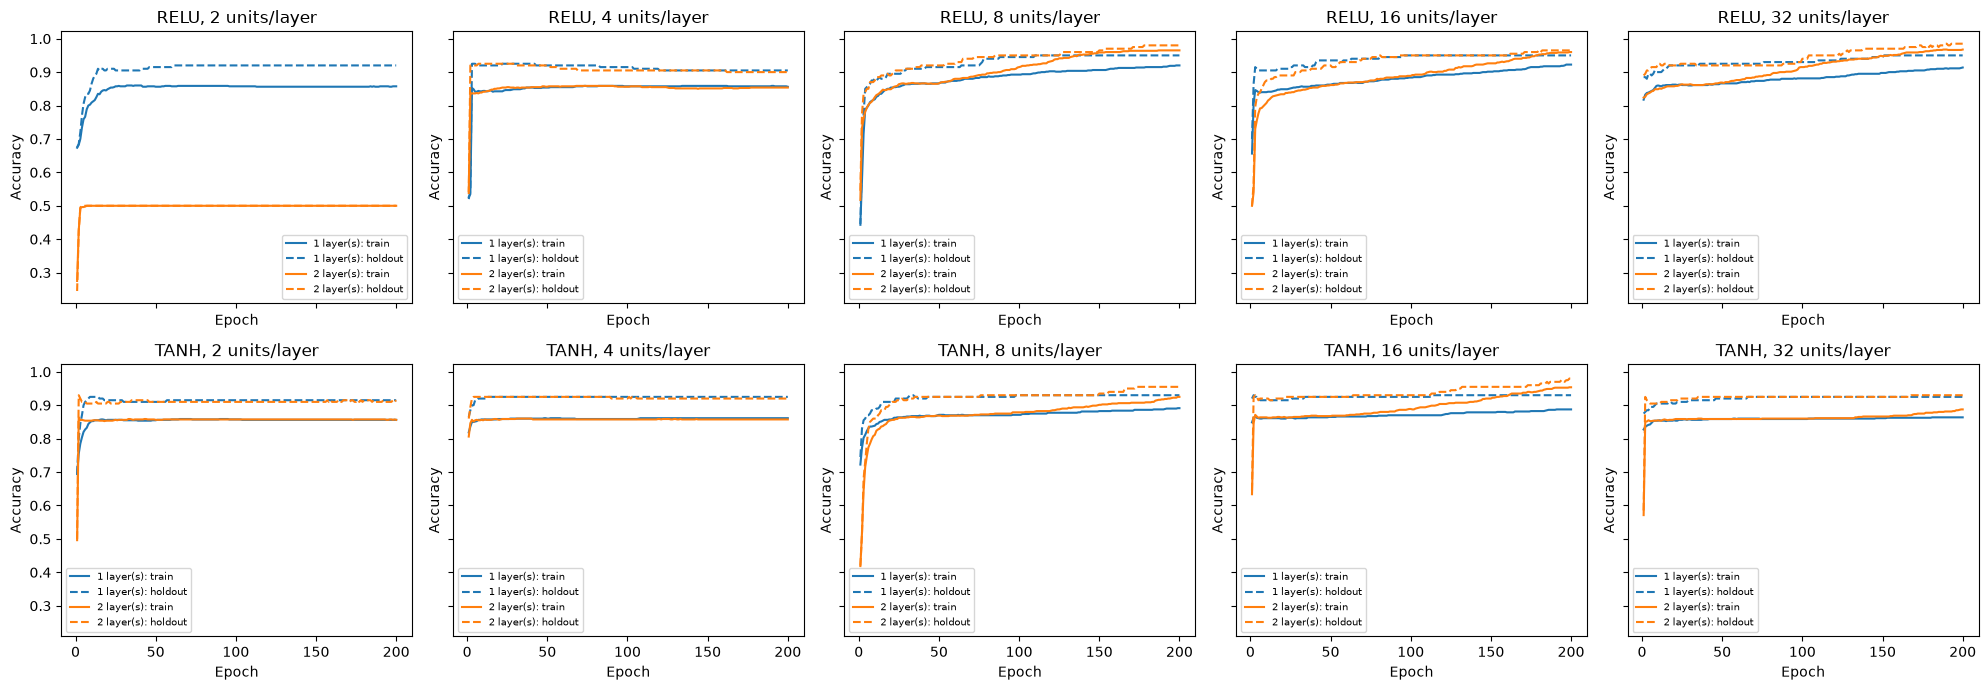

In [122]:
# Learning curves
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True, sharey=True)

for row, activation in enumerate(["relu", "tanh"]):
    for col, hidden_units in enumerate([2, 4, 8, 16, 32]):
        ax = axes[row, col]

        for n_hidden_layers, color in [(1, "tab:blue"), (2, "tab:orange")]:
            model = bin_models[(activation, hidden_units, n_hidden_layers)]
            epochs = np.arange(1, len(model.history["train_acc"]) + 1)

            ax.plot(epochs, model.history["train_acc"], color=color,
                    label=f"{n_hidden_layers} layer(s): train")
            ax.plot(epochs, model.history["holdout_acc"], color=color,
                    linestyle="--", label=f"{n_hidden_layers} layer(s): holdout")

        ax.set_title(f"{activation.upper()}, {hidden_units} units/layer")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

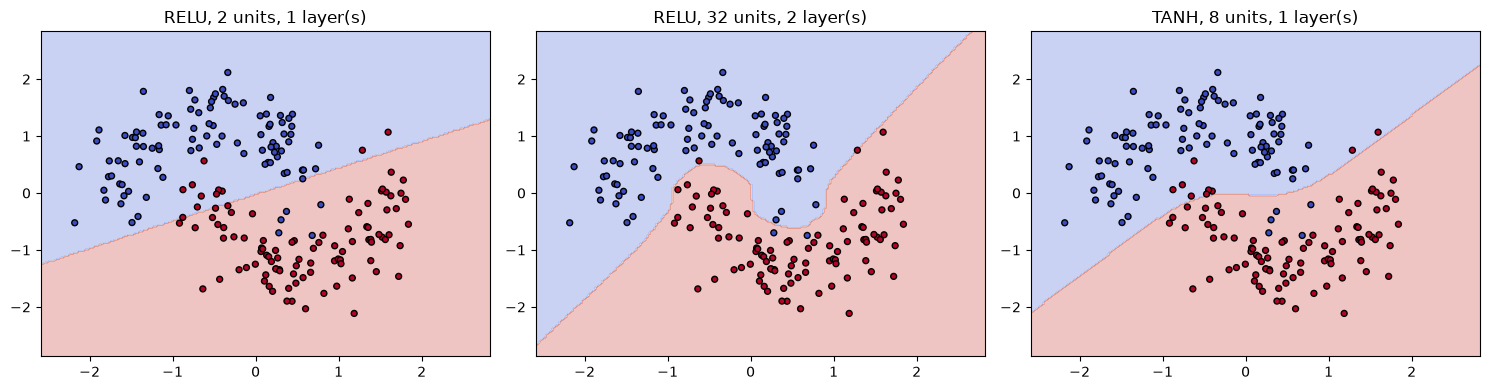

In [123]:
# Decision boundaries
def plot_boundary(ax, model, title):
    xx, yy = np.meshgrid(
        np.linspace(X_bin_train_scaled[:, 0].min() - 0.5, X_bin_train_scaled[:, 0].max() + 0.5, 200),
        np.linspace(X_bin_train_scaled[:, 1].min() - 0.5, X_bin_train_scaled[:, 1].max() + 0.5, 200)
    )
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    zz = model.predict(grid).numpy().reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_bin_holdout_scaled[:, 0], X_bin_holdout_scaled[:, 1],
               c=y_bin_holdout, cmap="coolwarm", edgecolor="k", s=18)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key in zip(axes, [("relu", 2, 1), ("relu", 32, 2), ("tanh", 8, 1)]):
    plot_boundary(ax, bin_models[key],
                  f"{key[0].upper()}, {key[1]} units, {key[2]} layer(s)")
plt.tight_layout()
plt.show()

**Analysis**

1 - How does the number of hidden units affect performance? The number of hidden units affect performance as small networks are too simple for this data. Most models with 2 or 4 hidden units reached around 90–93% holdout accuracy, but the two-layer ReLU model with 2 units struggled and only reached 50% accuracy. The two moons are curved and interlocked and the very small networks can only draw almost a straight line. However, the accuracy improved a lot with 8 units. One layer ReLU had a 92% train and 95% holdout accuracy. After 8 hidden units, the accuracy did not improve much more as one layer ReLU stayed at 95% holdout for 8, 16, and 32 hidden units. The training and holdout accuracy stayed pretty close together, so there was no real overfitting.

2 - What changes when using two layers instead of one? When adding a second layer, it helped a lot when the layers had enough units. When each layer had 8 units, ReLU holdout accuracy went from 95% to 98%. With 32 units, it reached 98.5% which was the best result. Tanh also improved, going from 93% to 98% with 16 units. Adding the second layer let the network bend its boundary more, so it can fit the two curved moons. 

3 - How does the activation function (ReLU vs. Tanh) influence results? ReLU worked better than tanh when the network had 8 or more units. With two layers of 32 units, ReLU got a 98.5% holdout accuracy and tanh had  a 93% holdout accuracy. ReLU also has a lower loss with the same number of epochs. however, tanh was better with very small networks as seen with the two layer and two unit tanh model getting a 91.5% holdout, but ReLU failed. 

## 2. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [124]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3, 
                           n_clusters_per_class=1, 
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

In [125]:
import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Split the dataset into 80% training and 20% holdout
X_train, X_holdout, y_train, y_holdout = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize without data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_holdout = scaler.transform(X_holdout)

# Convert features and labels to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_holdout = torch.tensor(X_holdout, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_holdout = torch.tensor(y_holdout, dtype=torch.long)

# One-hot encode three target classes
y_train_onehot = F.one_hot(y_train, num_classes=3).float()
y_holdout_onehot = F.one_hot(y_holdout, num_classes=3).float()


In [126]:
class MultiClassMLP:
    def __init__(self, input_size=2, hidden_units=(8,), output_size=3,
                 activation="relu", learning_rate=0.01, epochs=150):

        self.activation = activation
        self.learning_rate = learning_rate
        self.epochs = epochs

        sizes = [input_size, *hidden_units, output_size]
        self.weights = []
        self.biases = []

        # Initialize weights and biases for each layer
        for input_dim, output_dim in zip(sizes[:-1], sizes[1:]):
            if activation == "relu":
                scale = math.sqrt(2 / input_dim)
            else:
                scale = math.sqrt(1 / input_dim)

            W = (torch.randn(input_dim, output_dim) * scale).requires_grad_()
            b = torch.zeros(output_dim, requires_grad=True)

            self.weights.append(W)
            self.biases.append(b)

    def forward(self, X):
        h = X

        # Pass through hidden layers
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            h = h @ W + b

            if self.activation == "relu":
                h = F.relu(h)
            else:
                h = torch.tanh(h)

        # Output layer uses softmax
        logits = h @ self.weights[-1] + self.biases[-1]
        return F.softmax(logits, dim=1)

    def cost(self, predictions, y_true):
        # Categorical cross-entropy loss
        probabilities = predictions.clamp(min=1e-8)
        return -(y_true * torch.log(probabilities)).sum(dim=1).mean()

    def fit(self, X, y, X_holdout=None, y_holdout=None,
            batch_size=32):

        self.history = {
            "train_loss": [], "holdout_loss": [],
            "train_acc": [], "holdout_acc": []
        }

        for epoch in range(self.epochs):
            indices = torch.randperm(X.shape[0])

            for start in range(0, X.shape[0], batch_size):
                batch = indices[start:start + batch_size]

                predictions = self.forward(X[batch])
                loss = self.cost(predictions, y[batch])

                # Compute gradients
                loss.backward()

                # Manually update weights using mini-batch SGD
                with torch.no_grad():
                    for param in self.weights + self.biases:
                        param -= self.learning_rate * param.grad
                        param.grad.zero_()

            # Record training and holdout loss and accuracy
            with torch.no_grad():
                train_probs = self.forward(X)
                train_loss = self.cost(train_probs, y)
                train_acc = (
                    train_probs.argmax(dim=1) == y.argmax(dim=1)
                ).float().mean()

                self.history["train_loss"].append(train_loss.item())
                self.history["train_acc"].append(train_acc.item())

                if X_holdout is not None:
                    holdout_probs = self.forward(X_holdout)
                    holdout_loss = self.cost(holdout_probs, y_holdout)
                    holdout_acc = (
                        holdout_probs.argmax(dim=1) == y_holdout.argmax(dim=1)
                    ).float().mean()

                    self.history["holdout_loss"].append(holdout_loss.item())
                    self.history["holdout_acc"].append(holdout_acc.item())

        return self

    def predict(self, X):
        with torch.no_grad():
            probabilities = self.forward(X)
            return torch.argmax(probabilities, dim=1)

In [127]:
# Train and compare configurations
configs = [
    (activation, (units,) * layers)
    for activation in ["ReLU", "Tanh"]
    for units in [2, 4, 8, 16, 32]
    for layers in [1, 2]
]

results = []
models = {}

for activation, hidden_units in configs:
    torch.manual_seed(42)

    model = MultiClassMLP(
        hidden_units=hidden_units,
        activation=activation.lower(),
        learning_rate=0.01,
        epochs=150
    )

    model.fit(
        X_train, y_train_onehot,
        X_holdout, y_holdout_onehot
    )

    # Predict labels on both datasets
    train_pred = model.predict(X_train)
    holdout_pred = model.predict(X_holdout)

    train_acc = accuracy_score(
        y_train.numpy(), train_pred.numpy()
    )

    holdout_acc = accuracy_score(
        y_holdout.numpy(), holdout_pred.numpy()
    )

    results.append({
        "Activation": activation.lower(),
        "Hidden units per layer": hidden_units[0],
        "Hidden layers": len(hidden_units),
        "Train Accuracy": train_acc,
        "Holdout Accuracy": holdout_acc,
        "Train CCE": model.history["train_loss"][-1],
        "Holdout CCE": model.history["holdout_loss"][-1]
    })

    models[(activation, hidden_units)] = model

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Activation,Hidden units per layer,Hidden layers,Train Accuracy,Holdout Accuracy,Train CCE,Holdout CCE
0,relu,2,1,0.7850,0.840,0.6302,0.5537
1,relu,2,2,0.7375,0.775,0.7547,0.7014
2,relu,4,1,0.7900,0.825,0.6174,0.5721
3,relu,4,2,0.7925,0.835,0.6079,0.5419
4,relu,8,1,0.7962,0.825,0.5946,0.5523
5,relu,8,2,0.8012,0.845,0.5928,0.5455
6,relu,16,1,0.8025,0.835,0.5932,0.5533
7,relu,16,2,0.8050,0.840,0.5739,0.5589
8,relu,32,1,0.8038,0.850,0.5936,0.5556
9,relu,32,2,0.8000,0.830,0.5806,0.5478


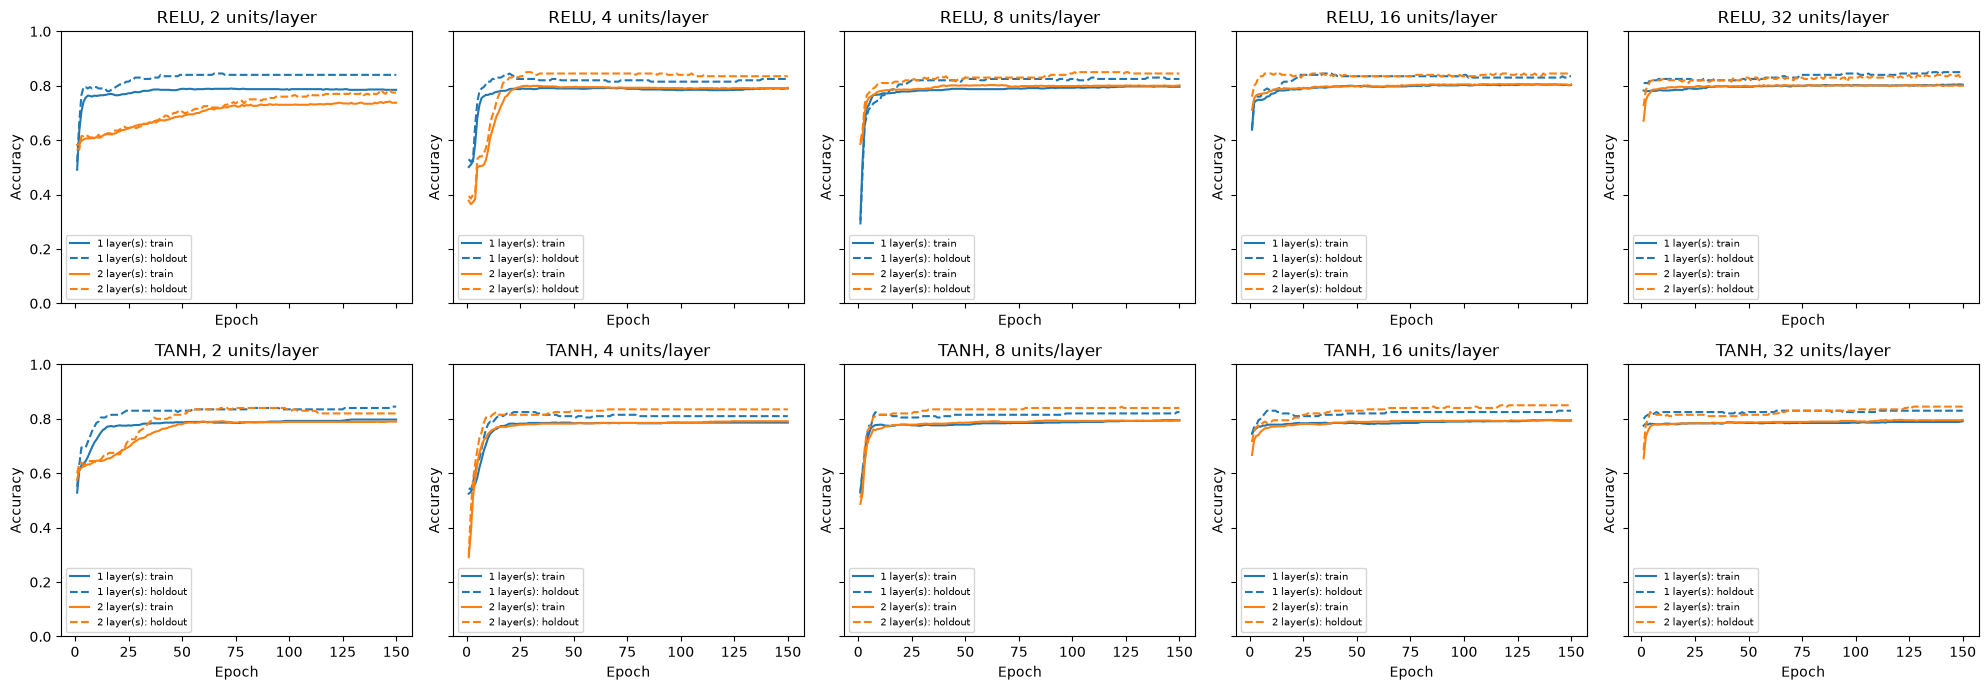

In [128]:

# Plot accuracy curves for each configuration
fig, axes = plt.subplots(
    2, 5, figsize=(20, 7),
    sharex=True, sharey=True
)

for row, activation in enumerate(["ReLU", "Tanh"]):
    for col, units in enumerate([2, 4, 8, 16, 32]):
        ax = axes[row, col]

        for layers, color in [(1, "tab:blue"), (2, "tab:orange")]:
            hidden_units = (units,) * layers
            model = models[(activation, hidden_units)]

            epochs = np.arange(
                1, len(model.history["train_acc"]) + 1
            )

            ax.plot(
                epochs, model.history["train_acc"],
                color=color,
                label=f"{layers} layer(s): train"
            )

            ax.plot(
                epochs, model.history["holdout_acc"],
                color=color, linestyle="--",
                label=f"{layers} layer(s): holdout"
            )

        ax.set_title(f"{activation.upper()}, {units} units/layer")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.set_ylim(0, 1)
        ax.legend(fontsize=7)

plt.tight_layout()
plt.show()


**Analysis**

1 - Increasing the number of hidden units generally helped improve performance, although the results weren't always consistent. For example, with two layers using ReLU, the holdout accuracy increased from 77.5% with 2 units per layer to 84.5% with 8 units, but then dropped to 83% with 32 units. Tanh showed a similar pattern, with its two-layer models reaching their highest accuracy of 85% at 16 units per layer. Overall, having more hidden units seemed to help the model learn more patterns in the data, but adding too many didn't necessarily lead to better results.

2 - Using two hidden layers improved performance for several configurations, but not all of them. With ReLU and 8 units per layer, the holdout accuracy increased from 82.5% with one layer to 84.5% with two layers. Tanh also improved from 83% to 85% with 16 units per layer. However, adding another layer actually hurt performance for some configurations, such as ReLU with 2 units, where accuracy dropped from 84% to 77.5%. This suggests that an additional layer can help the model learn more complex patterns, but it doesn't always lead to better performance.

3 - ReLU and Tanh both performed fairly well, with neither consistently outperforming the other across all configurations. ReLU reached its highest holdout accuracy of 85% with one layer of 32 units, while Tanh also reached 85% with two layers of 16 units each. ReLU performed better in some configurations, while Tanh had an advantage in others. Overall, the differences were pretty small, so both activation functions seemed to work well for this dataset. The number of hidden units and layers also played a role in determining which performed better.

## 3: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [129]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# keeping seperate regression variables
X_reg = X.copy()
y_reg = y.copy()

X_reg_train, X_reg_holdout, y_reg_train, y_reg_holdout = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

# fit scalers on training data only
reg_x_scaler = StandardScaler()
reg_y_scaler = StandardScaler()

X_reg_train_scaled = reg_x_scaler.fit_transform(X_reg_train)
X_reg_holdout_scaled = reg_x_scaler.transform(X_reg_holdout)

y_reg_train_scaled = reg_y_scaler.fit_transform(
    y_reg_train.reshape(-1, 1)
)
y_reg_holdout_scaled = reg_y_scaler.transform(
    y_reg_holdout.reshape(-1, 1)
)

# convert inputs/targets to tensors
X_reg_train_t = torch.tensor(X_reg_train_scaled, dtype=torch.float32)
X_reg_holdout_t = torch.tensor(X_reg_holdout_scaled, dtype=torch.float32)

y_reg_train_t = torch.tensor(y_reg_train_scaled, dtype=torch.float32)
y_reg_holdout_t = torch.tensor(y_reg_holdout_scaled, dtype=torch.float32)

print("Training-", X_reg_train_t.shape, y_reg_train_t.shape)
print("Holdout-", X_reg_holdout_t.shape, y_reg_holdout_t.shape)

Training- torch.Size([800, 2]) torch.Size([800, 1])
Holdout- torch.Size([200, 2]) torch.Size([200, 1])


In [130]:
# making the class
class RegressionMLP:
    def __init__(
        self,
        n_features,
        hidden_units=16,
        n_hidden_layers=1,
        activation="relu",
        seed=42
    ):
        if n_hidden_layers not in (1, 2):
            raise ValueError("Use one or two hidden layers.")

        if activation not in ("relu", "tanh"):
            raise ValueError("Use 'relu' or 'tanh'.")

        self.activation = activation
        self.weights = []
        self.biases = []

        generator = torch.Generator().manual_seed(seed)

        layer_sizes = (
            [n_features]
            + [hidden_units] * n_hidden_layers
            + [1]
        )

        for layer in range(len(layer_sizes) - 1):
            n_in = layer_sizes[layer]
            n_out = layer_sizes[layer + 1]
            is_hidden = layer < len(layer_sizes) - 2

            # He initialization for ReLU hidden layers;
            # Xavier-style initialization otherwise
            if is_hidden and activation == "relu":
                scale = np.sqrt(2.0 / n_in)
            else:
                scale = np.sqrt(2.0 / (n_in + n_out))

            weight = (
                torch.randn(n_in, n_out, generator=generator) * scale
            ).requires_grad_()

            bias = torch.zeros(
                1, n_out, requires_grad=True
            )

            self.weights.append(weight)
            self.biases.append(bias)

    def forward(self, X):
        output = X

        for layer in range(len(self.weights)):
            output = output @ self.weights[layer] + self.biases[layer]

            # Apply activation only to hidden layers
            if layer < len(self.weights) - 1:
                if self.activation == "relu":
                    output = torch.relu(output)
                else:
                    output = torch.tanh(output)

        return output

    def cost(self, predictions, targets):
        return ((predictions - targets) ** 2).mean()

    def fit(
        self,
        X,
        y,
        X_holdout,
        y_holdout,
        learning_rate=0.01,
        epochs=200,
        batch_size=32,
        seed=123
    ):
        generator = torch.Generator().manual_seed(seed)
        parameters = self.weights + self.biases

        self.history = {
            "train_mse": [],
            "holdout_mse": []
        }

        for epoch in range(epochs):
            # shuffle training observations each epoch
            order = torch.randperm(
                X.shape[0], generator=generator
            )

            for start in range(0, X.shape[0], batch_size):
                batch_indices = order[start:start + batch_size]

                predictions = self.forward(X[batch_indices])
                loss = self.cost(predictions, y[batch_indices])

                loss.backward()

                # manual sgd update
                with torch.no_grad():
                    for parameter in parameters:
                        parameter -= learning_rate * parameter.grad
                        parameter.grad.zero_()

            # recording performance after every epoch
            with torch.no_grad():
                train_mse = self.cost(self.forward(X), y).item()
                holdout_mse = self.cost(
                    self.forward(X_holdout), y_holdout
                ).item()

            self.history["train_mse"].append(train_mse)
            self.history["holdout_mse"].append(holdout_mse)

        return self

    def predict(self, X):
        with torch.no_grad():
            return self.forward(X).clone()

In [131]:
# train and compare configs

reg_results = []
reg_models = {}

for activation in ["relu", "tanh"]:
    for hidden_units in [8, 16, 32]:
        for n_hidden_layers in [1, 2]:

            model = RegressionMLP(
                n_features=X_reg_train_t.shape[1],
                hidden_units=hidden_units,
                n_hidden_layers=n_hidden_layers,
                activation=activation,
                seed=42
            )

            model.fit(
                X_reg_train_t,
                y_reg_train_t,
                X_reg_holdout_t,
                y_reg_holdout_t,
                learning_rate=0.01,
                epochs=200,
                batch_size=32
            )

            # converting predictions back to original target units
            train_predictions = reg_y_scaler.inverse_transform(
                model.predict(X_reg_train_t).numpy()
            ).ravel()

            holdout_predictions = reg_y_scaler.inverse_transform(
                model.predict(X_reg_holdout_t).numpy()
            ).ravel()

            train_mse = np.mean(
                (train_predictions - y_reg_train) ** 2
            )
            holdout_mse = np.mean(
                (holdout_predictions - y_reg_holdout) ** 2
            )

            key = (activation, hidden_units, n_hidden_layers)
            reg_models[key] = model

            reg_results.append({
                "Activation": activation,
                "Hidden units per layer": hidden_units,
                "Hidden layers": n_hidden_layers,
                "Train MSE": train_mse,
                "Holdout MSE": holdout_mse
            })

reg_results_df = pd.DataFrame(reg_results)

display(reg_results_df.round(2))

,Activation,Hidden units per layer,Hidden layers,Train MSE,Holdout MSE
0,relu,8,1,5391.54,5448.27
1,relu,8,2,5366.39,5502.81
2,relu,16,1,5380.49,5459.38
3,relu,16,2,5328.74,5573.82
4,relu,32,1,5388.73,5498.50
5,relu,32,2,5277.62,5536.89
6,tanh,8,1,5416.87,5509.35
7,tanh,8,2,5417.34,5485.72
8,tanh,16,1,5415.93,5463.54
9,tanh,16,2,5409.94,5456.34


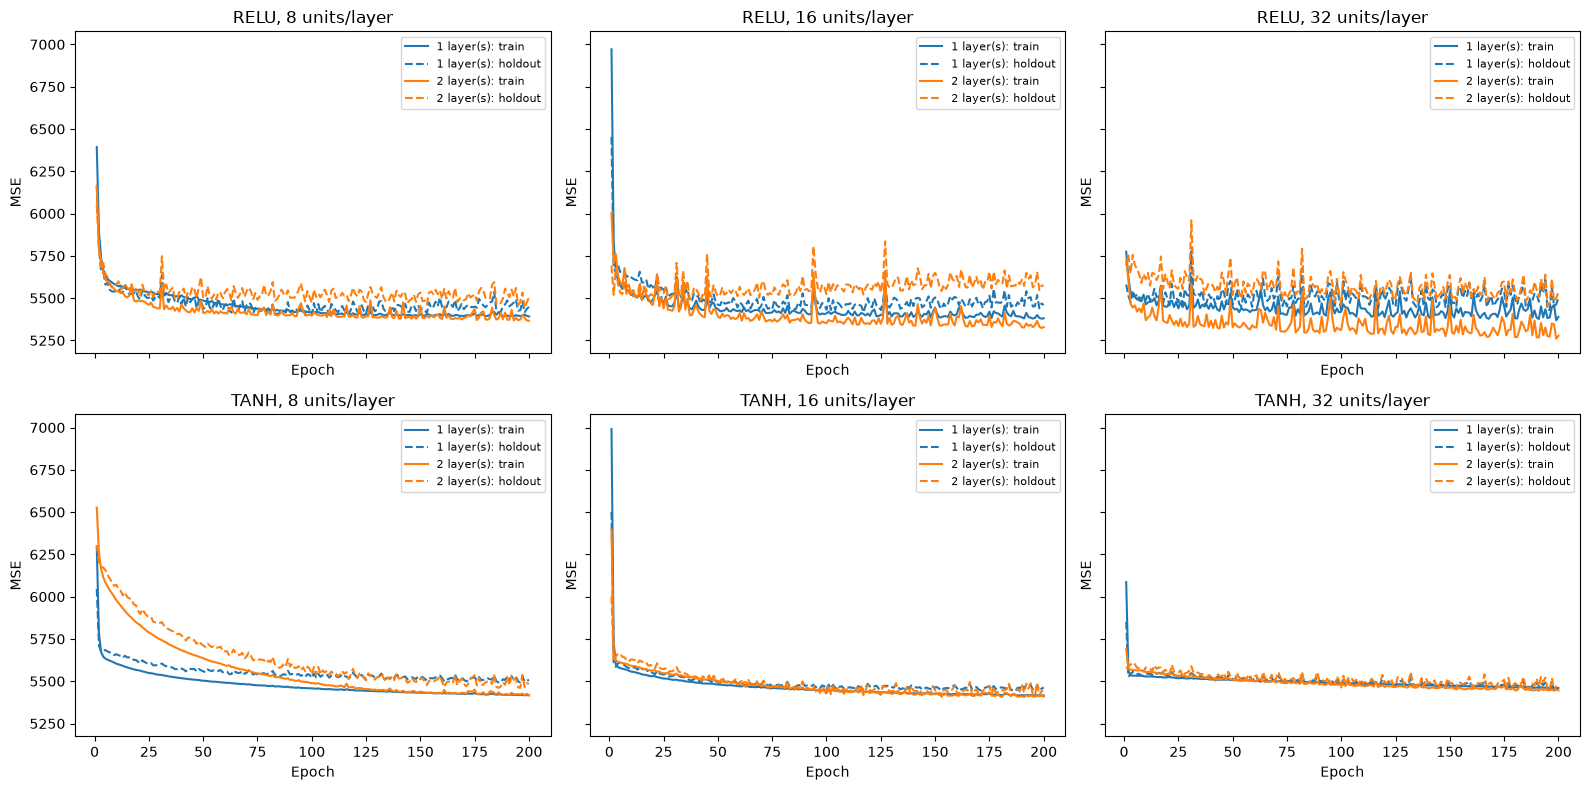

In [132]:
# plotting the learning curves
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 8),
    sharex=True,
    sharey=True
)

# converting standardized target mse to original target mse
target_variance = float(reg_y_scaler.scale_[0] ** 2)

for row, activation in enumerate(["relu", "tanh"]):
    for col, hidden_units in enumerate([8, 16, 32]):
        ax = axes[row, col]

        for n_hidden_layers, color in [(1, "tab:blue"), (2, "tab:orange")]:
            model = reg_models[
                (activation, hidden_units, n_hidden_layers)
            ]

            train_curve = (
                np.array(model.history["train_mse"]) * target_variance
            )
            holdout_curve = (
                np.array(model.history["holdout_mse"]) * target_variance
            )

            epochs = np.arange(1, len(train_curve) + 1)

            ax.plot(
                epochs,
                train_curve,
                color=color,
                label=f"{n_hidden_layers} layer(s): train"
            )
            ax.plot(
                epochs,
                holdout_curve,
                color=color,
                linestyle="--",
                label=f"{n_hidden_layers} layer(s): holdout"
            )

        ax.set_title(f"{activation.upper()}, {hidden_units} units/layer")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MSE")
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Analysis**

1 - How does the number of hidden units affect performance? - increasing the number of hidden units didn't consistently improve the holdout performance. For lone-layer ReLU models holdout MSE increased slightly from 5448.27 with 8 units to 5498.50 with 32 units while 2 layer ReLU models got lower training MSE as width increased without improving holdout MSE. Tanh performed best on the holdout set at 16 units for both depths suggesting that adding more units wasn't neccessarily useful for this dataset

2 - What changes when using two layers instead of one? - for ReLU adding a 2nd hidden layer lowered training MSE at every width but increased the holdout MSE suggesting some more overfitting. For example with 16 units per layer training MSE decreased from 5380.49 to 5328.74 while holdout MSE increased from 5459.38 to 5573.82. For Tanh a second layer kind of improved holdout performance at 8 and 16 units but made it slightly worse at 32 so additional depth didn't give a consistent advantage. 

3 - How does the activation function influence results? - ReLU generally got lower training MSE while Tanh gave smoother learning curves with fewer fluctuations especially in the wider models. Their holdout results were close, where ReLU performed better with one layer at each width while Tanh performed better with two layers at each width. The lowest final holdout MSE was 5448.27 from the one-layer ReLU model with 8 units, but these results come from a single split and initialization so they don't quite establish that ReLU is always better.

## 4. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

Looking back at our three classes, we ended up repeating a lot of the same code, especially when setting up the weights and biases, applying activation functions, and updating weights during training. Instead, we could have created a parent class called BaseMLP that handled these shared steps, then had BinaryMLP, MultiClassMLP, and RegressionMLP inherit from it. Each class could still have its own output activation function and cost function depending on the task, such as sigmoid with binary cross-entropy, softmax with categorical cross-entropy, or a linear output with MSE. We could also reuse the same general training process while allowing each class to calculate its own loss. This would have made our code shorter and easier to manage since we wouldn't need to make the same changes in multiple places.

## 5. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

For this lab, our group did a great job completing our roles individually, but struggled to work collaboratively throughout the entire process. We weren't completely on the same page at first about how to present our results and visualizations, which led to some inconsistencies between our sections. Although we went back and made our sections more consistent, we didn't spend enough time going over each other's work to fully understand every part of the lab. Next time, we plan to continue dividing up the sections, but spend more time discussing how we want to organize our results and reviewing each other's code as a group. That way, we can have a better understanding of the lab as a whole while also making sure our work fits together more smoothly.